![Python Banner](../../Image/05_04_doubleML.png)


# 4.4 Double ML with Instrumental Variables

**DML-IV** combines an instrument with cross-fitted nuisance models. The instrument $Z$ addresses endogeneity of the treatment $D$. Machine learning partials observed covariates out of $Y$, $D$, and $Z$. The final regression of outcome residuals on treatment residuals, using the instrument residuals as the instrument, is a cross-fitted cousin of two-stage least squares.


## Overview

| Node | Role |
|---|---|
| $Z$ | Instrument: affects $D$, and affects $Y$ only through $D$ |
| $C$ | Unobserved confounder |
| $D$ | Endogenous treatment |
| $Y$ | Outcome |

A regression of $Y$ on $D$ is biased when $C$ moves both. Partial linear DML without an instrument does not remove that bias. DML-IV does, under the usual IV assumptions (relevance, exclusion, and independence of $Z$ given the observed covariates).

With covariates $W$, the partially linear IV score residualizes all three variables:

$$\tilde Y = Y - \hat E[Y\mid W], \quad \tilde D = D - \hat E[D\mid W], \quad \tilde Z = Z - \hat E[Z\mid W]$$

$$\hat\theta = \frac{\sum_i \tilde Z_i \tilde Y_i}{\sum_i \tilde Z_i \tilde D_i}.$$

`InstrumentalVariable` in PyCausalML is the linear two-stage least squares version of the same idea, with a Bayesian bootstrap interval. `PartiallyLinearDML` is the no-instrument comparison.


## Implementation in Python

1. Simulate (Part A) or load (Part B) the sample.
2. Pass observed covariates into the nuisance regressions so a forest has something to split on.
3. Compute the naive mean difference.
4. Fit DML-IV and `PartiallyLinearDML` for ridge, random-forest, and gradient-boosting nuisances.
5. Compare estimates with the known effect in Part A, and across learners in Part B.

`Data/data_401k.csv` records **eligibility** (`e401`) and net financial assets, which is the partially linear 401(k) design. It does not contain a separate participation indicator, so the instrumental-variables contrast — eligibility as an instrument for an endogenous decision — is identified in the simulation, where $Z$, $D$, and $C$ are all generated. Part B estimates the eligibility effect on the real file and explains a linear CATE with SHAP.


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")

from pycausalml import InstrumentalVariable


Imported PyCausalML


In [3]:
def cross_fit_predict(X, y, n_splits, seed, kind="ridge"):
    """Out-of-fold predictions. kind is 'ridge', 'rf', or 'gbr'."""
    pred = np.zeros(len(y), dtype=float)
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, dtype=float)
    for fold, (tr, te) in enumerate(splitter.split(X)):
        model = _nuisance(kind, seed + fold)
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    return pred


def _nuisance(kind, seed):
    if kind == "ridge":
        return Ridge(alpha=1.0)
    if kind == "lasso":
        return Lasso(alpha=0.02, max_iter=8000)
    if kind == "rf":
        return RandomForestRegressor(
            n_estimators=40, max_depth=4, min_samples_leaf=5, random_state=seed, n_jobs=1,
        )
    if kind == "gbr":
        return GradientBoostingRegressor(
            n_estimators=40, max_depth=2, learning_rate=0.08, random_state=seed,
        )
    raise ValueError(kind)


def plot_beeswarm(explanation, title, max_display=8):
    imp = explanation.importance()
    order = np.argsort(imp)[-max_display:]
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(order) + 1.3))
    rng = np.random.default_rng(0)
    for i, j in enumerate(order):
        vals = explanation.values[:, j]
        raw = explanation.data[:, j]
        span = float(np.ptp(raw)) or 1.0
        color = (raw - np.min(raw)) / span
        jitter = rng.uniform(-0.16, 0.16, size=len(vals))
        ax.scatter(vals, np.full(len(vals), i) + jitter, c=color, cmap="coolwarm", s=18, alpha=0.9)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels([explanation.feature_names[j] for j in order])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("SHAP value")
    ax.set_title(title)
    fig.tight_layout()
    return fig


print("Helpers ready")


Helpers ready


In [4]:
def dml_iv(W, d, z, y, kind="ridge", n_splits=3, seed=0):
    y_res = y - cross_fit_predict(W, y, n_splits, seed, kind)
    d_res = d - cross_fit_predict(W, d, n_splits, seed + 3, kind)
    z_res = z - cross_fit_predict(W, z, n_splits, seed + 6, kind)
    denom = float(np.dot(z_res, d_res))
    theta = float(np.dot(z_res, y_res) / denom)
    psi = z_res * (y_res - theta * d_res) / np.mean(z_res * d_res)
    se = float(np.std(psi, ddof=1) / np.sqrt(len(psi)))
    return theta, se


class IVLinearCATE:
    """Linear CATE from a cross-fitted IV score, for SHAP."""

    def __init__(self, kind="ridge", n_splits=2, seed=0):
        self.kind = kind
        self.n_splits = n_splits
        self.seed = seed

    def fit(self, X, d, z, y, feature_names=None):
        X = np.asarray(X, dtype=float)
        y_res = y - cross_fit_predict(X, y, self.n_splits, self.seed, self.kind)
        d_res = d - cross_fit_predict(X, d, self.n_splits, self.seed + 3, self.kind)
        z_res = z - cross_fit_predict(X, z, self.n_splits, self.seed + 6, self.kind)
        phi = np.column_stack([np.ones(len(X)), X])
        design = z_res[:, None] * phi
        # Project y_res onto the instrumented treatment interacted with phi.
        # Use d_res on the left of the normal equations via 2SLS-style scaling:
        # solve (Zphi' Dphi) beta = Zphi' y, with Dphi = d_res * phi.
        d_design = d_res[:, None] * phi
        beta, *_ = np.linalg.lstsq(design.T @ d_design, design.T @ y_res, rcond=None)
        self.intercept_ = float(beta[0])
        self.feature_coef_ = np.asarray(beta[1:], dtype=float)
        self.feature_names_ = list(feature_names) if feature_names is not None else [f"x{j}" for j in range(X.shape[1])]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.feature_coef_

    predict_cate = predict


print("IV helpers ready")


IV helpers ready


## Part A: DML-IV with Synthetic Data

### Data-generating process

- $C$: binary unobserved confounder
- $Z$: binary instrument
- $D$: binary decision, increasing in $Z$ and in $C$
- $Y$: continuous outcome. The structural effect of $D$ is $-2$
- $W$: three noise covariates passed to the nuisance models

The naive difference in means is pulled upward by $C$.


In [5]:
def make_iv_sample(n=4000, seed=0):
    rng = np.random.default_rng(seed)
    confounder = rng.binomial(1, 0.5, size=n).astype(float)
    instrument = rng.binomial(1, 0.5, size=n).astype(float)
    covariates = rng.normal(size=(n, 3))
    logits = -0.4 + 1.6 * instrument + 1.7 * confounder
    propensity = 1.0 / (1.0 + np.exp(-logits))
    decision = rng.binomial(1, propensity).astype(float)
    outcome = -2.0 * decision + 4.0 * confounder + 0.15 * covariates[:, 0] + rng.normal(size=n)
    return covariates, instrument, decision, outcome


W, Z, D, Y = make_iv_sample()
naive = float(Y[D == 1].mean() - Y[D == 0].mean())
print("Naive mean difference:", round(naive, 3), "(true effect is -2)")


Naive mean difference: -0.497 (true effect is -2)


The naive estimate is far from $-2$. Units with $C = 1$ are both more likely to take the decision and have a higher baseline outcome.

### DML-IV versus standard DML


In [6]:
rows = [{"Estimator": "Naive mean difference", "Learner": "—", "Estimate": naive, "Std. err": np.nan}]
for kind in ("ridge", "rf", "gbr"):
    theta, se = dml_iv(W, D, Z, Y, kind=kind, seed=20)
    rows.append({"Estimator": "DML-IV", "Learner": kind, "Estimate": theta, "Std. err": se})
    plr = PartiallyLinearDML(
        discrete_treatment=True, n_splits=3, model_y=kind if kind != "gbr" else "gbr",
        n_estimators=40, random_state=20,
    )
    plr.fit(W, D, Y, feature_names=["W1", "W2", "W3"])
    summary = plr.average_treatment_effect()
    rows.append({
        "Estimator": "PartiallyLinearDML (no instrument)",
        "Learner": kind,
        "Estimate": summary["estimate"],
        "Std. err": summary["std.err"],
    })
comparison = pd.DataFrame(rows)
comparison.round(3)


,Estimator,Learner,Estimate,Std. err
0,Naive mean difference,—,-0.497,NaN
1,DML-IV,ridge,-1.767,0.247
2,PartiallyLinearDML (no instrument),ridge,-0.497,0.071
3,DML-IV,rf,-1.763,0.247
4,PartiallyLinearDML (no instrument),rf,-0.494,0.071
5,DML-IV,gbr,-1.785,0.247
6,PartiallyLinearDML (no instrument),gbr,-0.501,0.071


**Takeaway.** For every first-stage learner, DML-IV recovers a value near the structural effect of $-2$. `PartiallyLinearDML` has no instrument, so it stays near the confounded naive contrast.

### Minimal reference fit

Linear nuisances, and `InstrumentalVariable` (two-stage least squares) on the same sample.


In [7]:
theta_ref, se_ref = dml_iv(W, D, Z, Y, kind="ridge", n_splits=5, seed=1)
iv_linear = InstrumentalVariable(n_boot=80, random_state=1)
iv_linear.fit(Y, D, Z, X=W)
print("DML-IV ridge:", round(theta_ref, 3), "se", round(se_ref, 3))
print("InstrumentalVariable:", iv_linear.summary())


DML-IV ridge: -1.778 se 0.247
InstrumentalVariable: {'estimate': -1.7777615149187025, 'ci_lower': -2.2627837755876676, 'ci_upper': -1.3516220488076696, 'posterior_mean': -1.804244447222878}


### Second-stage coefficients

With a constant second stage the only coefficient is $\hat\theta$. The heterogeneous fit below lets the effect depend on $W$, which is what SHAP needs. The DGP's structural effect does not actually vary with $W$, so those slopes should be small and the average prediction should stay near $-2$.


In [8]:
het = IVLinearCATE(kind="ridge", n_splits=2, seed=3)
het.fit(W, D, Z, Y, feature_names=["W1", "W2", "W3"])
print("Intercept", round(het.intercept_, 3))
print(pd.DataFrame({"feature": het.feature_names_, "coef": het.feature_coef_}).round(3))
print("Mean predicted CATE", round(float(het.predict(W).mean()), 3))


Intercept -1.791
  feature   coef
0      W1  0.410
1      W2  0.177
2      W3  0.259
Mean predicted CATE -1.779


### Summary of Part A

| Estimator | What it recovers |
|---|---|
| Naive mean difference | Confounded contrast, pulled up by $C$ |
| DML-IV | Structural effect of the decision, near $-2$ |
| `PartiallyLinearDML` | The same confounded contrast, with covariates partialled out of the *observed* $W$ only |

With binary $Z$ and $D$ this is a LATE-style estimand for compliers. A constant second stage collapses it to one number, analogous to cross-fitted 2SLS.


## Part B: 401(k) Eligibility and Net Financial Assets

| Variable | Role in this extract |
|---|---|
| `net_tfa` | Outcome |
| `e401` | Eligibility, the treatment in the partially linear specification |
| `age`, `inc`, `fsize`, `educ`, `db`, `marr`, `twoearn`, `pira`, `hown` | Covariates |

Eligibility is the policy variable in the file. The simulation in Part A is where an unobserved confounder and a separate instrument are both present. Part B compares a naive mean difference with `PartiallyLinearDML` and `LinearDML`, then explains the linear CATE.


In [9]:
pension = pd.read_csv(data_dir / "data_401k.csv")
x_cols = ["age", "inc", "fsize", "educ", "db", "marr", "twoearn", "pira", "hown"]
Xp = pension[x_cols].to_numpy(dtype=float)
yp = pension["net_tfa"].to_numpy(dtype=float)
dp = pension["e401"].to_numpy(dtype=int)
rng = np.random.default_rng(3141)
train_parts = []
for arm in (0, 1):
    pool = np.flatnonzero(dp == arm)
    train_parts.append(rng.choice(pool, size=int(0.8 * len(pool)), replace=False))
tr = np.concatenate(train_parts)
te = np.setdiff1d(np.arange(len(dp)), tr)
naive_p = float(yp[dp == 1].mean() - yp[dp == 0].mean())
print("Train", len(tr), "Test", len(te), "naive difference", round(naive_p, 1))


Train 7931 Test 1984 naive difference 19559.3


### Train–test comparison


In [10]:
results = [{"Estimator": "Naive mean difference", "Learner": "—", "Estimate": naive_p, "Std. err": np.nan}]
for kind, label in (("ridge", "ridge"), ("rf", "rf"), ("gbr", "gbr")):
    model = PartiallyLinearDML(discrete_treatment=True, n_splits=3, model_y=kind, n_estimators=30, random_state=8)
    model.fit(Xp[tr], dp[tr], yp[tr], feature_names=x_cols)
    summary = model.average_treatment_effect()
    results.append({
        "Estimator": "PartiallyLinearDML",
        "Learner": label,
        "Estimate": summary["estimate"],
        "Std. err": summary["std.err"],
    })
result_table = pd.DataFrame(results)
result_table.round(1)


,Estimator,Learner,Estimate,Std. err
0,Naive mean difference,—,19559.3,NaN
1,PartiallyLinearDML,ridge,8478.7,1545.3
2,PartiallyLinearDML,rf,8674.2,1525.7
3,PartiallyLinearDML,gbr,9637.4,1563.2


### Visualize estimates


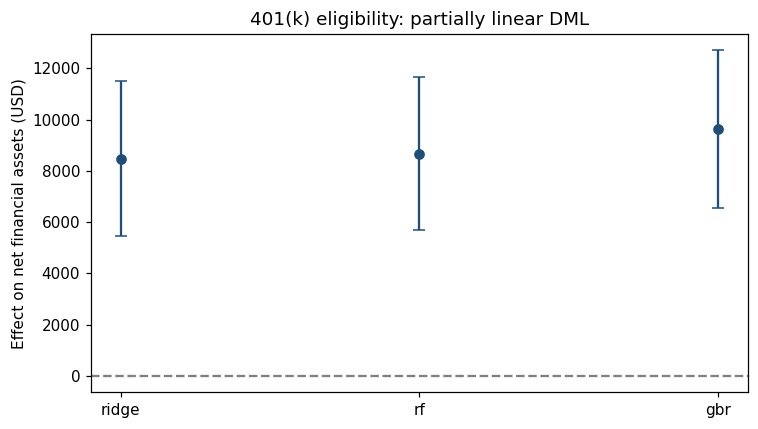

In [11]:
plot_df = result_table.dropna().reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.errorbar(
    np.arange(len(plot_df)),
    plot_df["Estimate"],
    yerr=1.96 * plot_df["Std. err"],
    fmt="o", color="#1F4E79", capsize=4,
)
ax.axhline(0, color="grey", ls="--")
ax.set_xticks(np.arange(len(plot_df)))
ax.set_xticklabels(plot_df["Learner"])
ax.set_ylabel("Effect on net financial assets (USD)")
ax.set_title("401(k) eligibility: partially linear DML")
fig.tight_layout()


**Reading the table.** Every `PartiallyLinearDML` row is the effect of eligibility after partialling out the observed covariates. The naive row is the raw mean difference. There is no simulation truth on this file; stability across learners is the check.

The DML-IV rows from Part A are the right comparison when participation is endogenous and eligibility is only an instrument. That second endogenous regressor is not in `data_401k.csv`.

### SHAP

`LinearDML` supplies $\hat\tau(X)$ on the training fold. Permutation SHAP uses a subsample of the test fold.


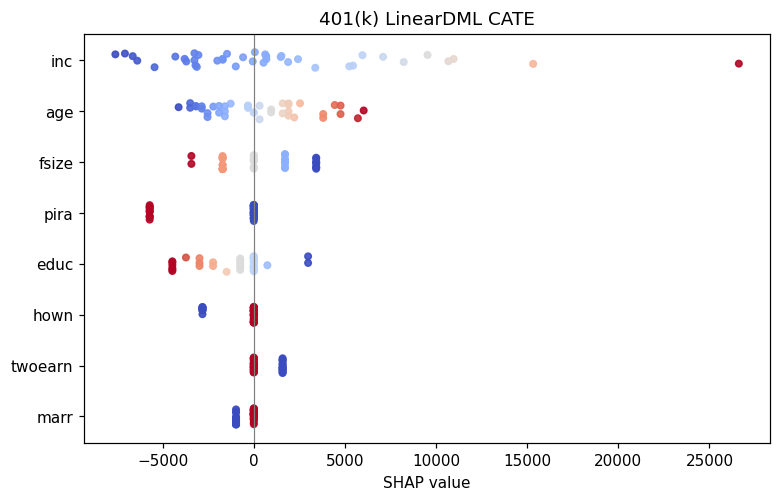

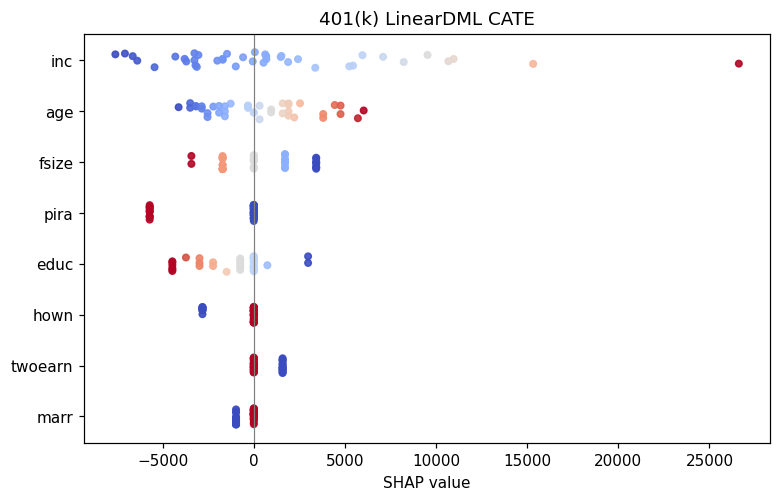

In [12]:
cate_model = LinearDML(discrete_treatment=True, n_splits=2, model_y="rf", n_estimators=30, random_state=9)
cate_model.fit(Xp[tr], dp[tr], yp[tr], feature_names=x_cols)
# Heterogeneous IV surface on the synthetic design, for a side-by-side reading of SHAP.
iv_surface = IVLinearCATE(kind="rf", n_splits=2, seed=4)
iv_surface.fit(W, D, Z, Y, feature_names=["W1", "W2", "W3"])
explanation = explain_cate(
    cate_model, Xp[te], feature_names=x_cols, max_samples=40, n_permutations=6, random_state=9,
)
iv_explanation = explain_cate(
    iv_surface, W, feature_names=["W1", "W2", "W3"], max_samples=40, n_permutations=6, random_state=4,
)
plot_beeswarm(explanation, "401(k) LinearDML CATE")


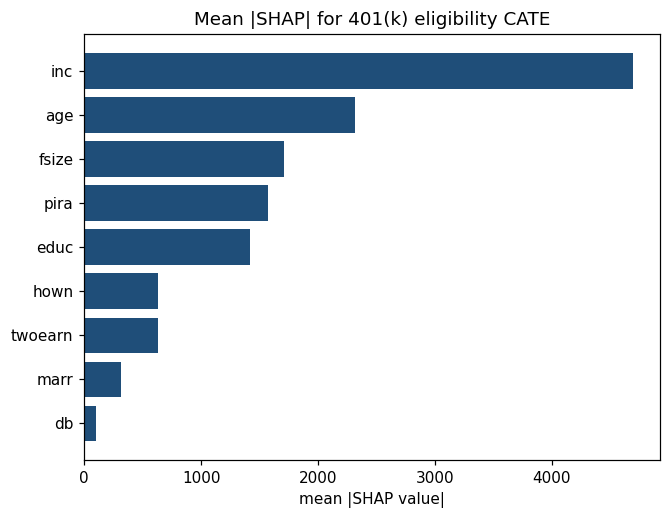

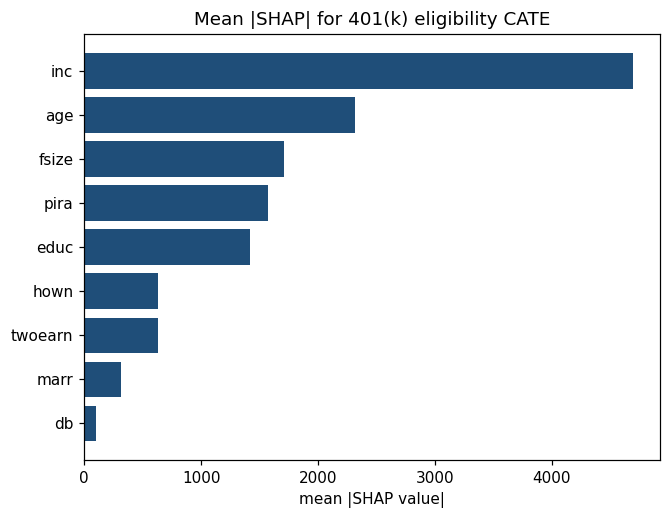

In [13]:
explanation.plot_importance(title="Mean |SHAP| for 401(k) eligibility CATE")


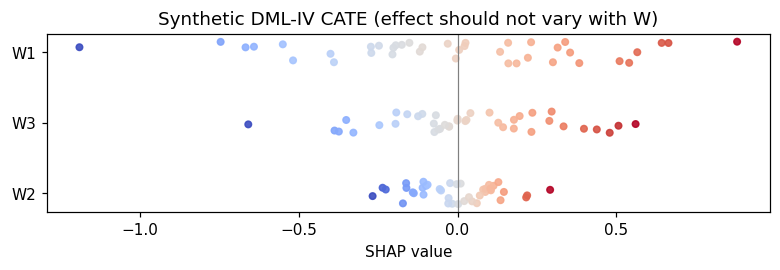

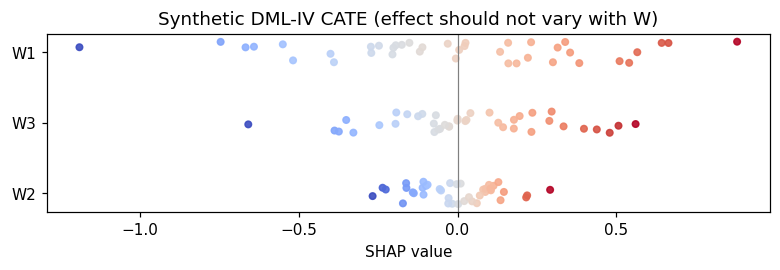

In [14]:
plot_beeswarm(iv_explanation, "Synthetic DML-IV CATE (effect should not vary with W)")


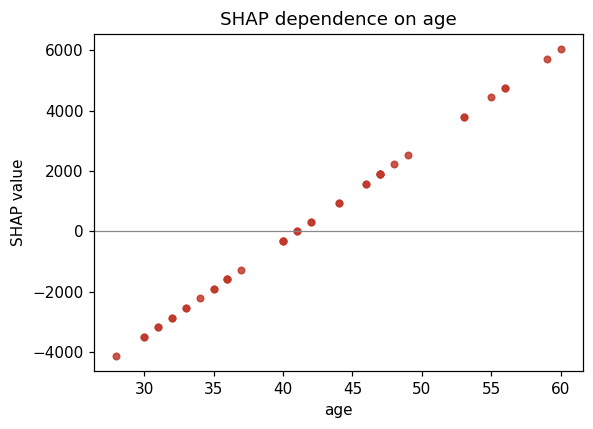

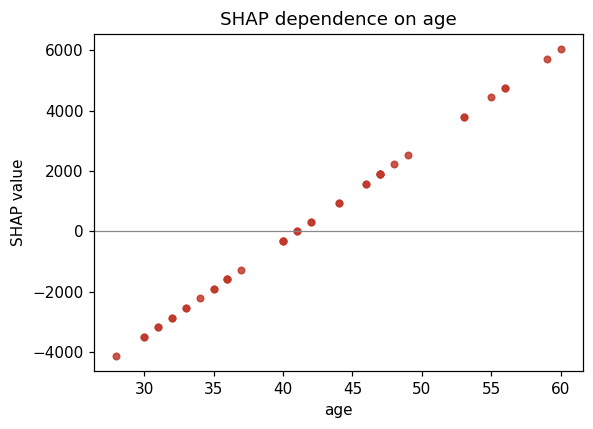

In [15]:
explanation.plot_dependence("age", title="SHAP dependence on age")


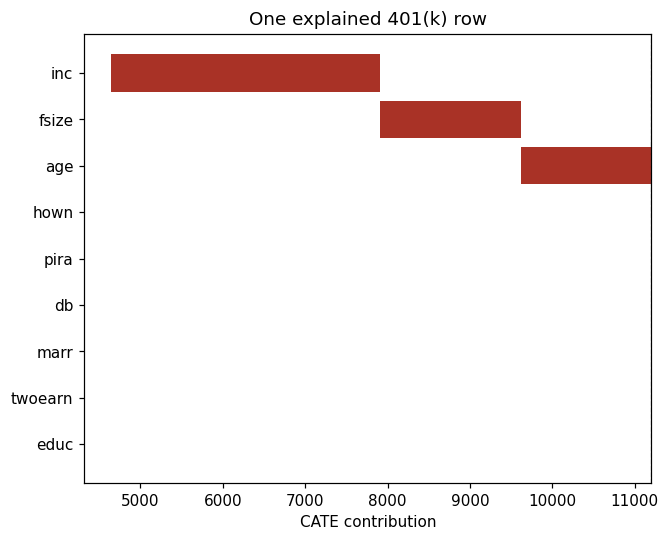

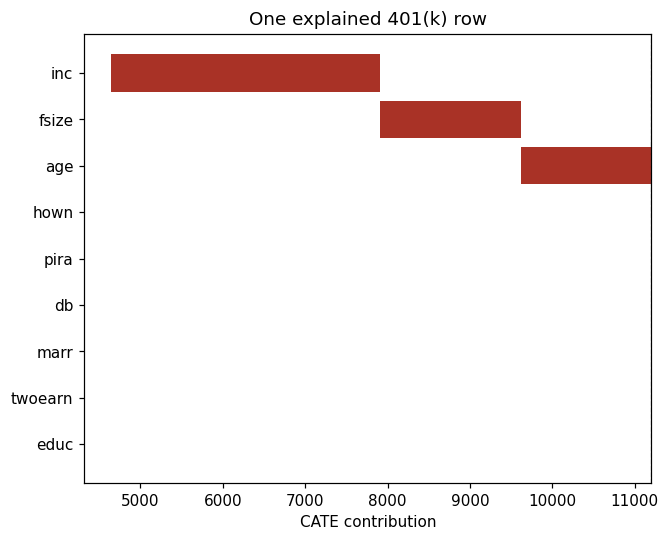

In [16]:
explanation.plot_waterfall(row=0, title="One explained 401(k) row")


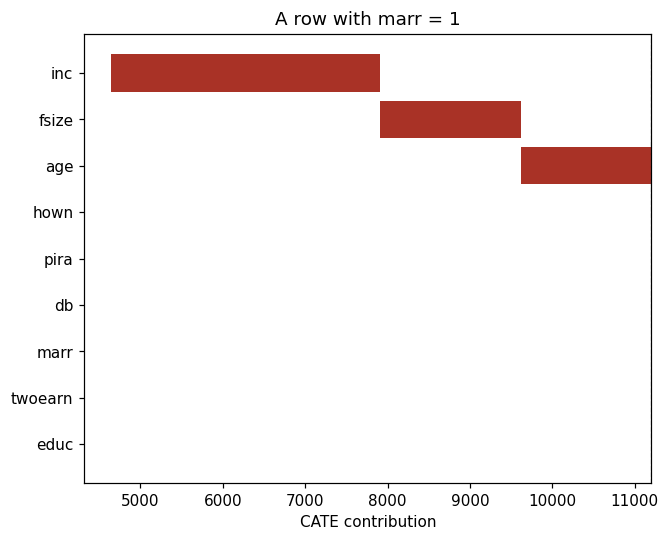

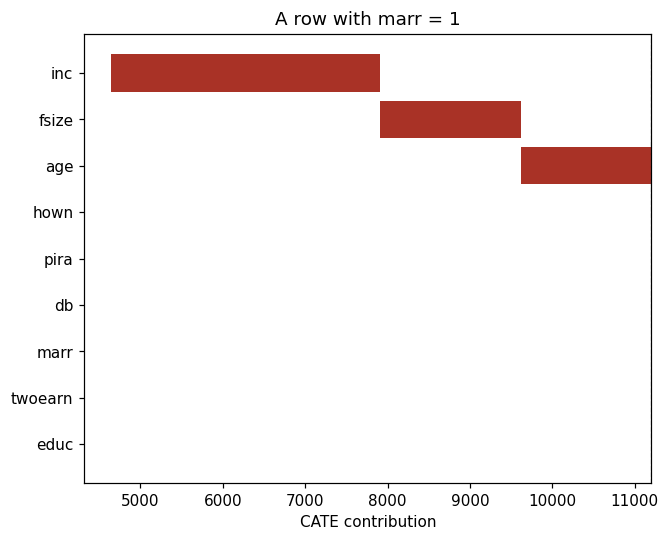

In [17]:
married = explanation.feature_names.index("marr")
hits = np.flatnonzero(explanation.data[:, married] == 1)
row = int(hits[0]) if len(hits) else 0
explanation.plot_waterfall(row=row, title="A row with marr = 1")


DML-IV and partially linear CATE surfaces answer different questions. On the simulation they should disagree in level, because only the IV score removes $C$. On the 401(k) extract the plotted SHAP values describe heterogeneity in the eligibility effect.

## Summary

| Component | Description |
|---|---|
| IV structure | $Z$ shifts $D$; $C$ otherwise confounds $D$ and $Y$ |
| DML-IV | Cross-fitted residuals of $Y$, $D$, and $Z$, then $\tilde Z$ instruments $\tilde D$ |
| `InstrumentalVariable` | Linear 2SLS with a bootstrap interval |
| `PartiallyLinearDML` | No instrument; biased when an unobserved confounder remains |
| 401(k) file | Eligibility effect via `PartiallyLinearDML` and `LinearDML` |
| SHAP | `explain_cate` on the linear CATE and on the simulated IV surface |

## References

- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
- Chernozhukov, V., Hansen, C., & Spindler, M. (2020). DoubleML. *Journal of Statistical Software*.
- [DoubleML user guide](https://docs.doubleml.org/stable/guide/index.html)
